In [1]:
from pathlib import Path
import sys
import json

import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.preprocessing import StandardScaler
from tensorflow.keras.callbacks import EarlyStopping

# Notebook'un konumu ne olursa olsun proje kökünü ve LSTM klasörünü bul.
def find_project_root(start: Path) -> Path:
    for directory in (start, *start.parents):
        if (directory / "n_cmapss" / "preprocessing").is_dir():
            return directory / "n_cmapss"
        if (directory / "preprocessing").is_dir() and (directory / "features").is_dir():
            return directory
    raise FileNotFoundError("n_cmapss proje kökü bulunamadı.")

PROJECT_ROOT = find_project_root(Path.cwd().resolve())
LSTM_DIR = PROJECT_ROOT / "models" / "LTSM"

for path in (PROJECT_ROOT, LSTM_DIR):
    path_string = str(path)
    if path_string not in sys.path:
        sys.path.insert(0, path_string)

from lstm_architectures import (
    build_vanilla_lstm,
    build_stacked_lstm,
    build_bidirectional_lstm,
    build_bilstm_attention,
)
from preprocessing.data_loader import load_window_metadata, split_windows_by_fold
from features.dl_sequences import build_sequences

windows = load_window_metadata()
X_lstm, y_lstm = build_sequences(windows)

with open(PROJECT_ROOT / "processed" / "split_folds.json", "r", encoding="utf-8") as fold_file:
    split_config = json.load(fold_file)

print("Proje kökü:", PROJECT_ROOT)
print("Toplam pencere:", len(windows))
print("Fold sayısı:", len(split_config["folds"]))

Proje kökü: /Users/helinkesip/Desktop/n_cmapss_guncel/n_cmapss
LSTM klasörü: /Users/helinkesip/Desktop/n_cmapss_guncel/n_cmapss/models/LTSM
Notebook proje yolları hazır.


In [8]:
from lstm_architectures import build_vanilla_lstm


model = build_vanilla_lstm(
    units=64,
    dropout=0.2
)

model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_4 (LSTM)                   │ (None, 64)             │        21,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,361 (91.25 KB)

 Trainable params: 23,361 (91.25 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
for units in [32, 64, 128]:
    model = build_vanilla_lstm(units=units)
    print(f"Units: {units} | Parametre: {model.count_params():,}")

Units: 32 | Parametre: 7,617
Units: 64 | Parametre: 23,361
Units: 128 | Parametre: 79,425


In [19]:
from preprocessing import data_loader

print([
    name for name in dir(data_loader)
    if "window" in name.lower()
])

['WINDOW_METADATA_PATH', 'WINDOW_SIZE', 'WindowRecord', 'load_window_metadata', 'split_windows_by_fold']


In [3]:
X_lstm, y_lstm = build_sequences(windows)

print("X boyutu:", X_lstm.shape)
print("y boyutu:", y_lstm.shape)

İşlenen pencere: 500/5270
İşlenen pencere: 1000/5270
İşlenen pencere: 1500/5270
İşlenen pencere: 2000/5270
İşlenen pencere: 2500/5270
İşlenen pencere: 3000/5270
İşlenen pencere: 3500/5270
İşlenen pencere: 4000/5270
İşlenen pencere: 4500/5270
İşlenen pencere: 5000/5270
X boyutu: (5270, 256, 18)
y boyutu: (5270,)


In [ ]:
from preprocessing.data_loader import split_windows_by_fold

train_windows, val_windows = split_windows_by_fold(
    windows, fold_number=1
)

print("Eğitim penceresi:", len(train_windows))
print("Doğrulama penceresi:", len(val_windows))

print("Eğitim motorları:", sorted(set(w.unit for w in train_windows)))
print("Doğrulama motorları:", sorted(set(w.unit for w in val_windows)))

Eğitim penceresi: 4416
Doğrulama penceresi: 854
Eğitim motorları: [5, 10, 16, 18, 20]
Doğrulama motorları: [2]


In [7]:
import gc
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.callbacks import EarlyStopping

SEED = 42
EPOCHS = 50
BATCH_SIZE = 64
UNITS_OPTIONS = [32, 64, 128]

vanilla_results = []
output_dir = PROJECT_ROOT / "processed" / "experiments"
output_dir.mkdir(parents=True, exist_ok=True)
vanilla_csv_path = output_dir / "vanilla_cross_validation_results.csv"

for fold_num in range(1, 7):
    train_windows, val_windows = split_windows_by_fold(windows, fold_num)

    train_units = {window.unit for window in train_windows}
    val_units = {window.unit for window in val_windows}

    train_indices = [
        index for index, window in enumerate(windows)
        if window.unit in train_units
    ]
    val_indices = [
        index for index, window in enumerate(windows)
        if window.unit in val_units
    ]

    X_train = X_lstm[train_indices]
    X_val = X_lstm[val_indices]
    y_train = y_lstm[train_indices]
    y_val = y_lstm[val_indices]

    feature_scaler = StandardScaler()
    n_features = X_train.shape[2]

    X_train_scaled = feature_scaler.fit_transform(
        X_train.reshape(-1, n_features)
    ).reshape(X_train.shape).astype("float32")

    X_val_scaled = feature_scaler.transform(
        X_val.reshape(-1, n_features)
    ).reshape(X_val.shape).astype("float32")

    y_train_mean = float(y_train.mean())
    y_train_std = float(y_train.std())

    y_train_scaled = ((y_train - y_train_mean) / y_train_std).astype("float32")
    y_val_scaled = ((y_val - y_train_mean) / y_train_std).astype("float32")

    validation_motor = next(iter(val_units))

    for units in UNITS_OPTIONS:
        print(f"Fold {fold_num}/6 | Motor {validation_motor} | Units {units}")

        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(SEED)

        model = build_vanilla_lstm(units=units, dropout=0.2)
        model.compile(
            optimizer="adam",
            loss="mse",
            metrics=["mae"]
        )

        history = model.fit(
            X_train_scaled,
            y_train_scaled,
            validation_data=(X_val_scaled, y_val_scaled),
            epochs=EPOCHS,
            batch_size=BATCH_SIZE,
            callbacks=[
                EarlyStopping(
                    monitor="val_loss",
                    patience=5,
                    restore_best_weights=True
                )
            ],
            verbose=0
        )

        scaled_predictions = model.predict(X_val_scaled, verbose=0).ravel()
        y_predictions = scaled_predictions * y_train_std + y_train_mean

        mae = float(np.mean(np.abs(y_val - y_predictions)))
        rmse = float(np.sqrt(np.mean((y_val - y_predictions) ** 2)))
        best_epoch = int(np.argmin(history.history["val_loss"]) + 1)

        vanilla_results.append({
            "fold": fold_num,
            "validation_motor": validation_motor,
            "model": "Vanilla LSTM",
            "units": units,
            "dropout": 0.2,
            "seed": SEED,
            "batch_size": BATCH_SIZE,
            "epochs": EPOCHS,
            "best_epoch": best_epoch,
            "train_rul_mean": y_train_mean,
            "train_rul_std": y_train_std,
            "val_mae": mae,
            "val_rmse": rmse,
        })

        pd.DataFrame(vanilla_results).to_csv(vanilla_csv_path, index=False)
        print(f"MAE: {mae:.3f} | RMSE: {rmse:.3f}")

        del model, history, scaled_predictions, y_predictions
        gc.collect()

vanilla_df = pd.DataFrame(vanilla_results)
display(vanilla_df)

vanilla_summary = vanilla_df.groupby("units").agg(
    mean_mae=("val_mae", "mean"),
    std_mae=("val_mae", "std"),
    mean_rmse=("val_rmse", "mean"),
    std_rmse=("val_rmse", "std"),
).round(3)

display(vanilla_summary)

Fold 1/6 | Motor 2 | Units 32
MAE: 4.714 | RMSE: 6.620
Fold 1/6 | Motor 2 | Units 64
MAE: 4.362 | RMSE: 6.180
Fold 1/6 | Motor 2 | Units 128
MAE: 4.144 | RMSE: 5.799
Fold 2/6 | Motor 5 | Units 32
MAE: 6.457 | RMSE: 9.397
Fold 2/6 | Motor 5 | Units 64
MAE: 6.983 | RMSE: 10.208
Fold 2/6 | Motor 5 | Units 128
MAE: 6.911 | RMSE: 10.153
Fold 3/6 | Motor 10 | Units 32
MAE: 5.150 | RMSE: 7.418
Fold 3/6 | Motor 10 | Units 64
MAE: 5.101 | RMSE: 7.238
Fold 3/6 | Motor 10 | Units 128
MAE: 6.288 | RMSE: 7.893
Fold 4/6 | Motor 16 | Units 32
MAE: 3.930 | RMSE: 5.698
Fold 4/6 | Motor 16 | Units 64
MAE: 3.366 | RMSE: 4.873
Fold 4/6 | Motor 16 | Units 128
MAE: 4.111 | RMSE: 5.643
Fold 5/6 | Motor 18 | Units 32
MAE: 3.302 | RMSE: 4.406
Fold 5/6 | Motor 18 | Units 64
MAE: 3.518 | RMSE: 4.966
Fold 5/6 | Motor 18 | Units 128
MAE: 4.315 | RMSE: 5.678
Fold 6/6 | Motor 20 | Units 32
MAE: 4.946 | RMSE: 6.142
Fold 6/6 | Motor 20 | Units 64
MAE: 5.173 | RMSE: 6.778
Fold 6/6 | Motor 20 | Units 128
MAE: 5.876 | RM

,fold,validation_motor,model,units,dropout,seed,batch_size,epochs,best_epoch,train_rul_mean,train_rul_std,val_mae,val_rmse
0,1,2,Vanilla LSTM,32,0.2,42,64,50,11,37.340355,22.536390,4.714190,6.620434
1,1,2,Vanilla LSTM,64,0.2,42,64,50,7,37.340355,22.536390,4.362399,6.179939
2,1,2,Vanilla LSTM,128,0.2,42,64,50,20,37.340355,22.536390,4.143533,5.798637
3,2,5,Vanilla LSTM,32,0.2,42,64,50,19,35.645657,21.084978,6.456596,9.396539
4,2,5,Vanilla LSTM,64,0.2,42,64,50,9,35.645657,21.084978,6.983356,10.208055
5,2,5,Vanilla LSTM,128,0.2,42,64,50,5,35.645657,21.084978,6.911087,10.153186
6,3,10,Vanilla LSTM,32,0.2,42,64,50,25,36.484356,22.098986,5.149736,7.417980
7,3,10,Vanilla LSTM,64,0.2,42,64,50,12,36.484356,22.098986,5.100680,7.238408
8,3,10,Vanilla LSTM,128,0.2,42,64,50,6,36.484356,22.098986,6.288121,7.892854
9,4,16,Vanilla LSTM,32,0.2,42,64,50,14,38.267216,22.867607,3.929830,5.697671


,mean_mae,std_mae,mean_rmse,std_rmse
units,,,,
32,4.750,1.085,6.613,1.693
64,4.750,1.332,6.707,1.961
128,5.274,1.235,7.250,1.853


In [8]:
import gc
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.callbacks import EarlyStopping

SEED = 42
EPOCHS = 50
BATCH_SIZE = 64

architecture_builders = {
    "Vanilla LSTM": lambda: build_vanilla_lstm(units=32, dropout=0.2),
    "Stacked LSTM": build_stacked_lstm,
    "Bidirectional LSTM": build_bidirectional_lstm,
    "BiLSTM + Attention": build_bilstm_attention,
}

architecture_results = []
architecture_csv_path = output_dir / "architecture_cross_validation_results.csv"

for architecture_name, builder in architecture_builders.items():
    print(f"\n=== {architecture_name} ===")

    for fold_num in range(1, 7):
        train_windows, val_windows = split_windows_by_fold(windows, fold_num)
        train_units = {window.unit for window in train_windows}
        val_units = {window.unit for window in val_windows}

        train_indices = [
            index for index, window in enumerate(windows)
            if window.unit in train_units
        ]
        val_indices = [
            index for index, window in enumerate(windows)
            if window.unit in val_units
        ]

        X_train = X_lstm[train_indices]
        X_val = X_lstm[val_indices]
        y_train = y_lstm[train_indices]
        y_val = y_lstm[val_indices]

        feature_scaler = StandardScaler()
        n_features = X_train.shape[2]

        X_train_scaled = feature_scaler.fit_transform(
            X_train.reshape(-1, n_features)
        ).reshape(X_train.shape).astype("float32")

        X_val_scaled = feature_scaler.transform(
            X_val.reshape(-1, n_features)
        ).reshape(X_val.shape).astype("float32")

        y_train_mean = float(y_train.mean())
        y_train_std = float(y_train.std())
        y_train_scaled = ((y_train - y_train_mean) / y_train_std).astype("float32")
        y_val_scaled = ((y_val - y_train_mean) / y_train_std).astype("float32")

        validation_motor = next(iter(val_units))

        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(SEED)

        model = builder()
        model.compile(
            optimizer="adam",
            loss="mse",
            metrics=["mae"]
        )

        history = model.fit(
            X_train_scaled,
            y_train_scaled,
            validation_data=(X_val_scaled, y_val_scaled),
            epochs=EPOCHS,
            batch_size=BATCH_SIZE,
            callbacks=[
                EarlyStopping(
                    monitor="val_loss",
                    patience=5,
                    restore_best_weights=True
                )
            ],
            verbose=0
        )

        scaled_predictions = model.predict(X_val_scaled, verbose=0).ravel()
        y_predictions = scaled_predictions * y_train_std + y_train_mean

        mae = float(np.mean(np.abs(y_val - y_predictions)))
        rmse = float(np.sqrt(np.mean((y_val - y_predictions) ** 2)))
        best_epoch = int(np.argmin(history.history["val_loss"]) + 1)

        architecture_results.append({
            "architecture": architecture_name,
            "fold": fold_num,
            "validation_motor": validation_motor,
            "seed": SEED,
            "batch_size": BATCH_SIZE,
            "epochs": EPOCHS,
            "best_epoch": best_epoch,
            "train_rul_mean": y_train_mean,
            "train_rul_std": y_train_std,
            "val_mae": mae,
            "val_rmse": rmse,
        })

        pd.DataFrame(architecture_results).to_csv(
            architecture_csv_path,
            index=False
        )

        print(
            f"Fold {fold_num}/6 | Motor {validation_motor} | "
            f"MAE: {mae:.3f} | RMSE: {rmse:.3f}"
        )

        del model, history, scaled_predictions, y_predictions
        gc.collect()

architecture_df = pd.DataFrame(architecture_results)
architecture_summary = architecture_df.groupby("architecture").agg(
    mean_mae=("val_mae", "mean"),
    std_mae=("val_mae", "std"),
    mean_rmse=("val_rmse", "mean"),
    std_rmse=("val_rmse", "std"),
).sort_values("mean_mae").round(3)

motor5_summary = architecture_df[architecture_df["validation_motor"] == 5].copy()

print("\nOrtalama mimari sonuçları")
display(architecture_summary)

print("\nMotor 5 mimari karşılaştırması")
display(
    motor5_summary[[
        "architecture", "fold", "validation_motor",
        "best_epoch", "val_mae", "val_rmse"
    ]].sort_values("val_mae")
)


=== Vanilla LSTM ===
Fold 1/6 | Motor 2 | MAE: 4.714 | RMSE: 6.620
Fold 2/6 | Motor 5 | MAE: 6.457 | RMSE: 9.397
Fold 3/6 | Motor 10 | MAE: 5.150 | RMSE: 7.418
Fold 4/6 | Motor 16 | MAE: 3.930 | RMSE: 5.698
Fold 5/6 | Motor 18 | MAE: 3.302 | RMSE: 4.406
Fold 6/6 | Motor 20 | MAE: 4.946 | RMSE: 6.142

=== Stacked LSTM ===
Fold 1/6 | Motor 2 | MAE: 3.960 | RMSE: 5.768
Fold 2/6 | Motor 5 | MAE: 7.664 | RMSE: 11.026
Fold 3/6 | Motor 10 | MAE: 4.623 | RMSE: 6.848
Fold 4/6 | Motor 16 | MAE: 5.450 | RMSE: 7.491
Fold 5/6 | Motor 18 | MAE: 3.735 | RMSE: 5.008
Fold 6/6 | Motor 20 | MAE: 5.627 | RMSE: 6.790

=== Bidirectional LSTM ===
Fold 1/6 | Motor 2 | MAE: 3.985 | RMSE: 5.609
Fold 2/6 | Motor 5 | MAE: 6.902 | RMSE: 10.214
Fold 3/6 | Motor 10 | MAE: 4.922 | RMSE: 6.925
Fold 4/6 | Motor 16 | MAE: 4.392 | RMSE: 5.781
Fold 5/6 | Motor 18 | MAE: 4.284 | RMSE: 5.893
Fold 6/6 | Motor 20 | MAE: 5.475 | RMSE: 6.976

=== BiLSTM + Attention ===
Fold 1/6 | Motor 2 | MAE: 4.938 | RMSE: 6.938
Fold 2/6 | M

,mean_mae,std_mae,mean_rmse,std_rmse
architecture,,,,
Vanilla LSTM,4.750,1.085,6.613,1.693
Bidirectional LSTM,4.994,1.073,6.900,1.728
Stacked LSTM,5.176,1.437,7.155,2.091
BiLSTM + Attention,5.463,1.053,7.414,1.560



Motor 5 mimari karşılaştırması


,architecture,fold,validation_motor,best_epoch,val_mae,val_rmse
1,Vanilla LSTM,2,5,19,6.456596,9.396539
19,BiLSTM + Attention,2,5,6,6.627449,10.002106
13,Bidirectional LSTM,2,5,4,6.902309,10.214113
7,Stacked LSTM,2,5,12,7.663598,11.026455


In [3]:

import pandas as pd

motor_df = pd.DataFrame({
    "motor": [w.unit for w in windows],
    "rul": y_lstm
})

rul_summary = motor_df.groupby("motor")["rul"].agg(
    ["count", "min", "max", "mean", "std"]
).round(2)

display(rul_summary)


,count,min,max,mean,std
motor,,,,,
2,854,0.0,74.0,37.150002,21.530001
5,1034,0.0,88.0,44.130001,25.940001
10,955,0.0,81.0,41.040001,23.230000
16,768,0.0,62.0,31.700001,18.260000
18,890,0.0,70.0,34.380001,20.760000
20,769,0.0,65.0,32.680000,19.240000


In [4]:

import numpy as np
import pandas as pd

# Her pencere için 18 sensörün zamansal ortalaması
sensor_means = X_lstm.mean(axis=1)

sensor_df = pd.DataFrame(
    sensor_means,
    columns=[f"Sensor_{i+1}" for i in range(18)]
)

sensor_df["motor"] = [w.unit for w in windows]

# Her motorun sensör ortalamaları
motor_sensor_means = sensor_df.groupby("motor").mean()

display(motor_sensor_means.round(3))


,Sensor_1,Sensor_2,Sensor_3,Sensor_4,Sensor_5,Sensor_6,Sensor_7,Sensor_8,Sensor_9,Sensor_10,Sensor_11,Sensor_12,Sensor_13,Sensor_14,Sensor_15,Sensor_16,Sensor_17,Sensor_18
motor,,,,,,,,,,,,,,,,,,
2,21595.560547,0.619,69.211998,475.683014,560.518982,1323.771973,1649.995972,1109.793945,10.977,8.332,11.145,13.815,212.604996,216.216003,8.163,2022.157959,8218.822266,2.312
5,21459.675781,0.621,68.869003,476.365997,561.064026,1324.219971,1650.457031,1110.391968,11.028,8.381,11.196,13.869,212.897995,216.520996,8.192,2021.254028,8220.385742,2.312
10,21513.560547,0.618,68.822998,475.898987,560.468994,1323.004028,1648.708008,1109.574951,10.986,8.348,11.154,13.817,212.214996,215.824997,8.172,2019.463989,8216.216797,2.304
16,21397.060547,0.614,68.573997,475.851990,560.168030,1322.244995,1647.671021,1109.842041,11.004,8.370,11.172,13.826,212.229996,215.843994,8.208,2016.817993,8213.829102,2.302
18,22207.376953,0.629,69.848999,474.381989,559.513000,1323.417969,1651.166992,1109.555054,10.798,8.178,10.962,13.605,210.343994,213.901993,7.997,2026.904053,8218.431641,2.289
20,21279.359375,0.617,68.905998,476.656006,561.293030,1326.571045,1651.848022,1113.012939,11.082,8.417,11.250,13.931,214.904007,218.567001,8.256,2022.534058,8229.090820,2.335


In [6]:

# Her pencere içinde sensörlerin zamansal standart sapması
sensor_stds = X_lstm.std(axis=1)

std_df = pd.DataFrame(
    sensor_stds,
    columns=[f"Sensor_{i+1}" for i in range(18)]
)

std_df["motor"] = [w.unit for w in windows]

motor_sensor_stds = std_df.groupby("motor").mean()

display(motor_sensor_stds.round(3))


,Sensor_1,Sensor_2,Sensor_3,Sensor_4,Sensor_5,Sensor_6,Sensor_7,Sensor_8,Sensor_9,Sensor_10,Sensor_11,Sensor_12,Sensor_13,Sensor_14,Sensor_15,Sensor_16,Sensor_17,Sensor_18
motor,,,,,,,,,,,,,,,,,,
2,222.447998,0.005,1.673,0.731,1.996,7.675,13.790,6.630,0.125,0.070,0.126,0.192,4.690,4.739,0.104,18.045000,25.792999,0.066
5,218.815994,0.005,1.756,0.697,2.025,7.915,14.327,6.811,0.125,0.069,0.127,0.196,4.895,4.945,0.105,18.882999,26.576000,0.069
10,218.020004,0.005,1.824,0.676,2.076,8.177,14.815,7.054,0.125,0.067,0.127,0.195,4.902,4.952,0.106,19.495001,27.528999,0.069
16,210.841003,0.004,1.748,0.661,1.995,7.861,14.228,6.789,0.120,0.066,0.122,0.186,4.630,4.677,0.101,18.638000,26.395000,0.065
18,218.397003,0.004,1.555,0.691,1.866,7.120,12.806,6.335,0.119,0.067,0.121,0.181,4.343,4.389,0.102,16.375000,23.825001,0.061
20,212.477997,0.005,1.779,0.684,2.077,8.137,14.690,7.026,0.129,0.067,0.131,0.200,5.030,5.082,0.107,19.209000,27.326000,0.071


İşlenen pencere: 500/5270
İşlenen pencere: 1000/5270
İşlenen pencere: 1500/5270
İşlenen pencere: 2000/5270
İşlenen pencere: 2500/5270
İşlenen pencere: 3000/5270
İşlenen pencere: 3500/5270
İşlenen pencere: 4000/5270
İşlenen pencere: 4500/5270
İşlenen pencere: 5000/5270


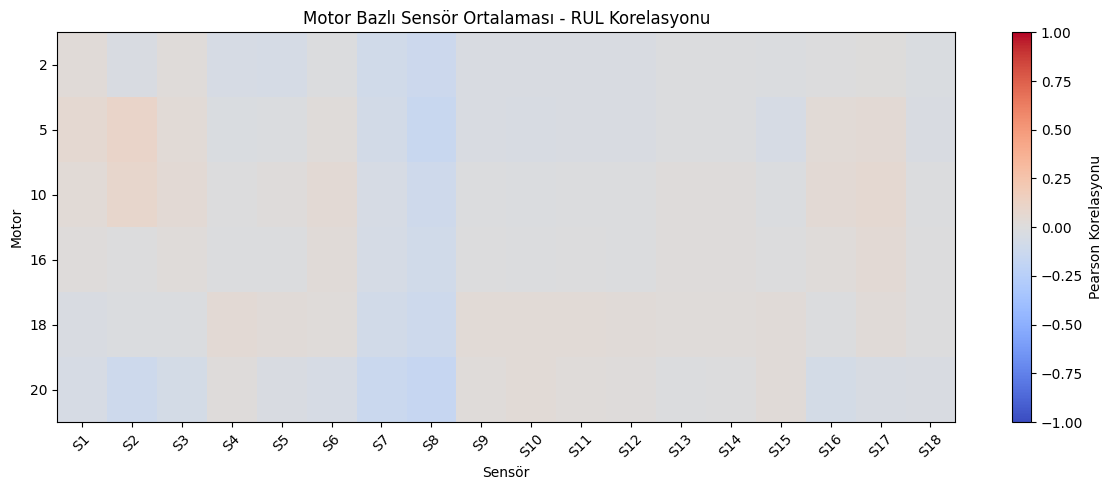

In [3]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Tek başına çalıştırıldığında bile proje yollarını ve veriyi hazırla.
def find_project_root(start: Path) -> Path:
    for directory in (start, *start.parents):
        if (directory / "n_cmapss" / "preprocessing").is_dir():
            return directory / "n_cmapss"
        if (directory / "preprocessing").is_dir() and (directory / "features").is_dir():
            return directory
    raise FileNotFoundError("n_cmapss proje kökü bulunamadı.")

PROJECT_ROOT = find_project_root(Path.cwd().resolve())
LSTM_DIR = PROJECT_ROOT / "models" / "LTSM"

for path in (PROJECT_ROOT, LSTM_DIR):
    path_string = str(path)
    if path_string not in sys.path:
        sys.path.insert(0, path_string)

from preprocessing.data_loader import load_window_metadata
from features.dl_sequences import build_sequences

if "windows" not in globals():
    windows = load_window_metadata()

if "X_lstm" not in globals() or "y_lstm" not in globals():
    X_lstm, y_lstm = build_sequences(windows)

sensor_means = X_lstm.mean(axis=1)

corr_df = pd.DataFrame(
    sensor_means,
    columns=[f"Sensor_{i+1}" for i in range(18)]
)
corr_df["motor"] = [w.unit for w in windows]
corr_df["rul"] = y_lstm

correlation_rows = {}

for motor, motor_df in corr_df.groupby("motor"):
    numeric_df = motor_df.drop(columns="motor")
    motor_correlations = numeric_df.corr()["rul"].drop("rul")
    correlation_rows[int(motor)] = motor_correlations

correlations = pd.DataFrame(correlation_rows).T

plt.figure(figsize=(12, 5))
plt.imshow(correlations, aspect="auto", cmap="coolwarm",
           vmin=-1, vmax=1)
plt.colorbar(label="Pearson Korelasyonu")
plt.xticks(range(18), [f"S{i+1}" for i in range(18)], rotation=45)
plt.yticks(range(len(correlations)), correlations.index)
plt.xlabel("Sensör")
plt.ylabel("Motor")
plt.title("Motor Bazlı Sensör Ortalaması - RUL Korelasyonu")
plt.tight_layout()
plt.show()

Batch/dropout sonuçları


,batch_size,dropout,learning_rate,units,seed,fold,validation_motor,best_epoch,train_rul_mean,train_rul_std,val_mae,val_rmse
0,32,0.1,0.001,32,42,1,2,13,37.340355,22.536390,4.350531,6.007730
1,32,0.1,0.001,32,42,2,5,9,35.645657,21.084978,6.590332,9.933934
2,32,0.1,0.001,32,42,3,10,13,36.484356,22.098986,5.192693,7.568456
3,32,0.1,0.001,32,42,4,16,12,38.267216,22.867607,5.124858,6.686844
4,32,0.1,0.001,32,42,5,18,9,37.905708,22.645046,4.787473,6.798257
...,...,...,...,...,...,...,...,...,...,...,...,...
67,128,0.4,0.001,32,42,2,5,6,35.645657,21.084978,9.297495,12.890676
68,128,0.4,0.001,32,42,3,10,9,36.484356,22.098986,5.521520,7.629895
69,128,0.4,0.001,32,42,4,16,12,38.267216,22.867607,4.301316,6.192928
70,128,0.4,0.001,32,42,5,18,15,37.905708,22.645046,3.705442,4.966056


Batch/dropout genel özetleri


mean_mae  std_mae  mean_rmse  std_rmse
batch_size dropout learning_rate                                        
64         0.1     0.001             4.739    1.090      6.631     1.414
           0.2     0.001             4.750    1.085      6.613     1.693
           0.3     0.001             4.865    1.157      6.724     1.674
           0.4     0.001             4.886    1.115      6.614     1.627
128        0.2     0.001             4.980    1.441      6.784     1.812
           0.1     0.001             5.127    1.450      7.070     1.825
32         0.2     0.001             5.259    1.260      7.198     1.549
           0.4     0.001             5.283    1.360      7.228     1.810
128        0.4     0.001             5.303    2.057      7.281     2.880
32         0.1     0.001             5.307    0.790      7.442     1.365
128        0.3     0.001             5.590    2.258      7.613     2.798
32         0.3     0.001             5.700    1.433      7.867     1.793

Motor 5 batch/dropout özetleri


motor5_mae  motor5_rmse
batch_size dropout learning_rate                         
64         0.2     0.001               6.457        9.397
           0.4     0.001               6.553        9.262
32         0.1     0.001               6.590        9.934
64         0.3     0.001               6.646        9.480
           0.1     0.001               6.729        9.445
128        0.3     0.001               6.959        9.860
32         0.2     0.001               7.361        9.929
           0.4     0.001               7.429       10.016
128        0.2     0.001               7.716       10.269
           0.1     0.001               7.724       10.438
32         0.3     0.001               7.923       10.650
128        0.4     0.001               9.297       12.891

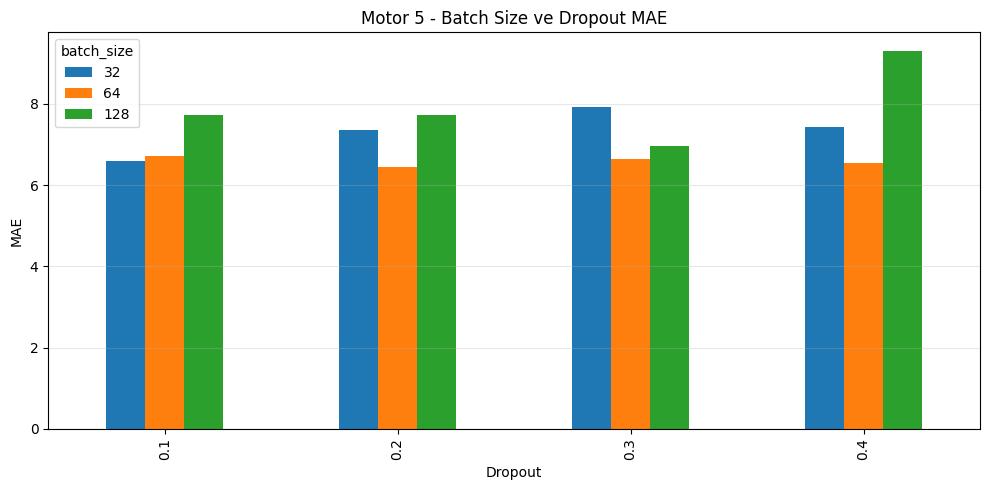

In [12]:
import pandas as pd
import matplotlib.pyplot as plt

# Kayıtlı eğitim sonucu; model tekrar eğitilmez.
output_csv = PROJECT_ROOT / "processed" / "experiments" / "vanilla_batch_dropout_results.csv"
batch_dropout_df = pd.read_csv(output_csv)

overall_summary = batch_dropout_df.groupby(
    ["batch_size", "dropout", "learning_rate"]
).agg(
    mean_mae=("val_mae", "mean"),
    std_mae=("val_mae", "std"),
    mean_rmse=("val_rmse", "mean"),
    std_rmse=("val_rmse", "std"),
).sort_values(["mean_mae", "std_mae"])

motor5_summary = batch_dropout_df[
    batch_dropout_df["validation_motor"] == 5
].groupby(["batch_size", "dropout", "learning_rate"]).agg(
    motor5_mae=("val_mae", "mean"),
    motor5_rmse=("val_rmse", "mean"),
).sort_values("motor5_mae")

print("Batch/dropout sonuçları")
display(batch_dropout_df)

print("Batch/dropout genel özetleri")
display(overall_summary.round(3))

print("Motor 5 batch/dropout özetleri")
display(motor5_summary.round(3))

motor5_table = batch_dropout_df[
    batch_dropout_df["validation_motor"] == 5
].pivot(index="dropout", columns="batch_size", values="val_mae")

ax = motor5_table.plot(kind="bar", figsize=(10, 5))
ax.set_title("Motor 5 - Batch Size ve Dropout MAE")
ax.set_xlabel("Dropout")
ax.set_ylabel("MAE")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Learning-rate genel özetleri


mean_mae  std_mae  mean_rmse
learning_rate dropout batch_size                              
0.0010        0.1     64             4.739    1.090      6.631
              0.2     64             4.750    1.085      6.613
0.0005        0.1     64             5.114    1.440      6.953
              0.2     64             5.476    1.561      7.433
0.0001        0.1     64             5.770    1.734      7.719
              0.2     64             6.118    2.210      8.096

Motor 5 learning-rate özetleri


motor5_mae  motor5_rmse
learning_rate dropout batch_size                         
0.0010        0.2     64               6.457        9.397
              0.1     64               6.729        9.445
0.0005        0.2     64               6.887        9.825
              0.1     64               6.894        9.553
0.0001        0.1     64               7.768       10.545
              0.2     64               8.697       11.563

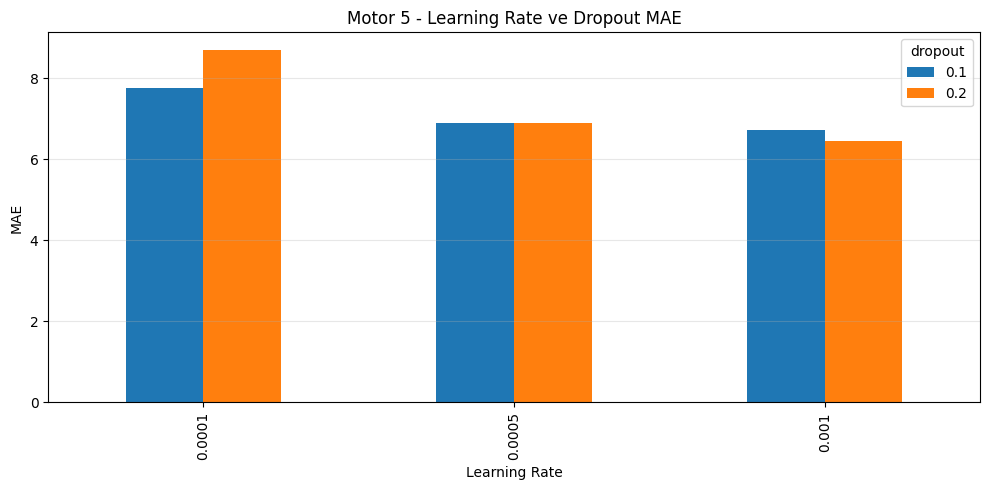

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

learning_csv = PROJECT_ROOT / "processed" / "experiments" / "vanilla_learning_rate_results.csv"
learning_df = pd.read_csv(learning_csv)

learning_summary = learning_df.groupby(
    ["learning_rate", "dropout", "batch_size"]
).agg(
    mean_mae=("val_mae", "mean"),
    std_mae=("val_mae", "std"),
    mean_rmse=("val_rmse", "mean"),
).sort_values(["mean_mae", "std_mae"])

motor5_summary = learning_df[
    learning_df["validation_motor"] == 5
].groupby(["learning_rate", "dropout", "batch_size"]).agg(
    motor5_mae=("val_mae", "mean"),
    motor5_rmse=("val_rmse", "mean"),
).sort_values("motor5_mae")

print("Learning-rate genel özetleri")
display(learning_summary.round(3))
print("Motor 5 learning-rate özetleri")
display(motor5_summary.round(3))

motor5_table = learning_df[
    learning_df["validation_motor"] == 5
].pivot(index="learning_rate", columns="dropout", values="val_mae")

ax = motor5_table.plot(kind="bar", figsize=(10, 5))
ax.set_title("Motor 5 - Learning Rate ve Dropout MAE")
ax.set_xlabel("Learning Rate")
ax.set_ylabel("MAE")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Genel multi-seed özetleri


,mean_mae,std_mae,mean_rmse
seed,,,
42,4.750,1.085,6.613
2024,4.942,1.281,6.741
21,5.243,1.333,7.133
123,5.356,1.575,7.260
314,5.601,1.630,7.669


Motor multi-seed özetleri


,mean_mae,std_mae,mean_rmse
validation_motor,,,
2,5.016,0.278,6.690
5,7.072,0.798,9.908
10,5.507,0.473,7.657
16,4.770,0.860,6.765
18,3.046,0.157,4.166
20,5.659,0.556,7.314


Motor 5 seed sonuçları


,seed,fold,validation_motor,best_epoch,val_mae,val_rmse
1,21,2,5,10,6.734,9.557
7,42,2,5,19,6.457,9.397
13,123,2,5,9,7.900,10.794
19,314,2,5,8,7.959,11.036
25,2024,2,5,19,6.311,8.755


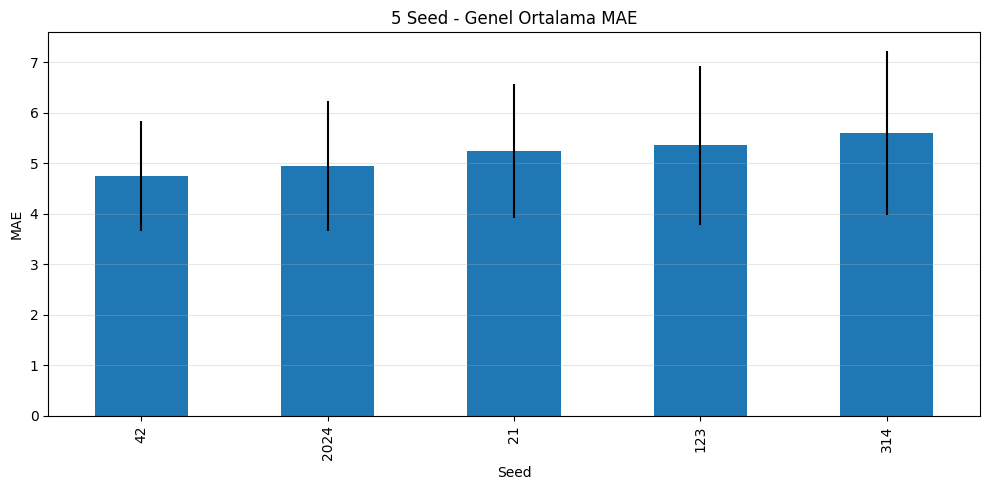

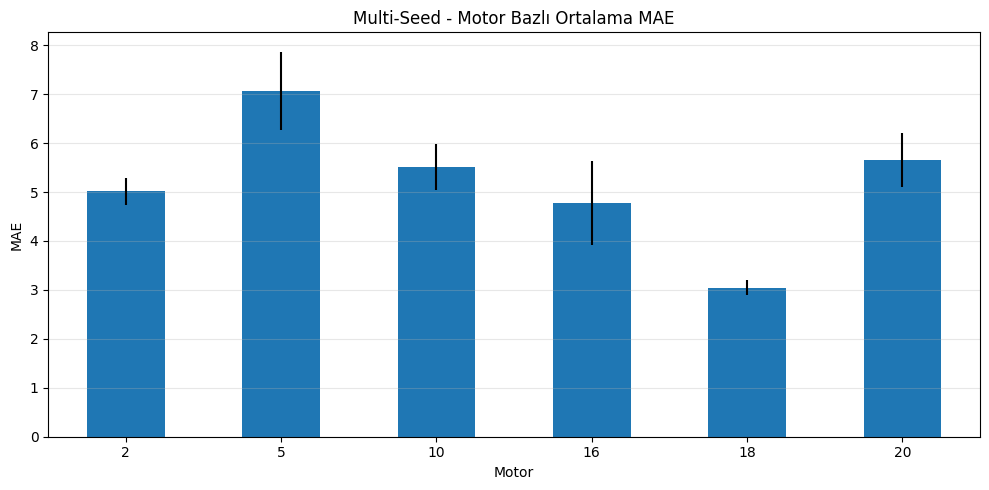

In [14]:
import pandas as pd
import matplotlib.pyplot as plt

multiseed_csv = PROJECT_ROOT / "processed" / "experiments" / "vanilla_multiseed_results.csv"
multiseed_df = pd.read_csv(multiseed_csv)

seed_summary = multiseed_df.groupby("seed").agg(
    mean_mae=("val_mae", "mean"),
    std_mae=("val_mae", "std"),
    mean_rmse=("val_rmse", "mean"),
).sort_values("mean_mae")

motor_summary = multiseed_df.groupby("validation_motor").agg(
    mean_mae=("val_mae", "mean"),
    std_mae=("val_mae", "std"),
    mean_rmse=("val_rmse", "mean"),
).sort_index()

motor5_seed_summary = multiseed_df[
    multiseed_df["validation_motor"] == 5
][["seed", "fold", "validation_motor", "best_epoch", "val_mae", "val_rmse"]]

print("Genel multi-seed özetleri")
display(seed_summary.round(3))
print("Motor multi-seed özetleri")
display(motor_summary.round(3))
print("Motor 5 seed sonuçları")
display(motor5_seed_summary.round(3))

ax = seed_summary.reset_index().plot(
    x="seed", y="mean_mae", kind="bar", yerr="std_mae",
    figsize=(10, 5), legend=False,
)
ax.set_title("5 Seed - Genel Ortalama MAE")
ax.set_xlabel("Seed")
ax.set_ylabel("MAE")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

ax = motor_summary.reset_index().plot(
    x="validation_motor", y="mean_mae", kind="bar", yerr="std_mae",
    figsize=(10, 5), legend=False,
)
ax.set_title("Multi-Seed - Motor Bazlı Ortalama MAE")
ax.set_xlabel("Motor")
ax.set_ylabel("MAE")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()